In [67]:
##PROJECT TITLE:
##Bank Customer Churn Analysis using Machine Learning

In [70]:
##Problem Statement:
##The bank wants to identify customers who are likely to leave.
##This helps the bank take actions to retain customers and reduce churn.

In [71]:
##Project Summary:
##This project aims to predict bank customer churn using machine learning.
##The goal is to identify customers likely to leave and help the bank improve retention strategies.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("Downloads/archive/Churn_Modelling.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [68]:
##Dataset Description:
##Dataset contains 10,000 bank customers with features like age, balance, geography, and churn status.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [4]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [8]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [9]:
df=df.drop(['RowNumber','CustomerId','Surname'],axis=1)

In [10]:
df.isnull().sum()

CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [12]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

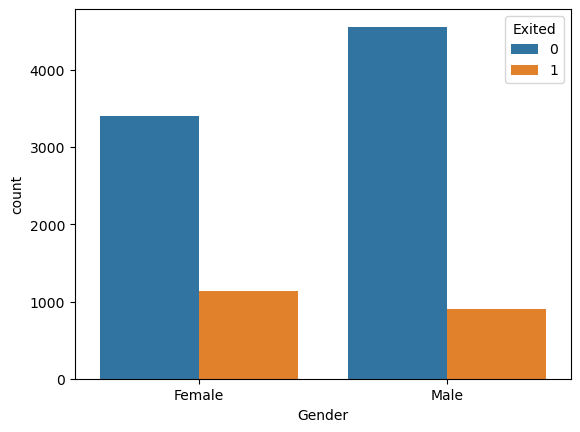

In [13]:
sns.countplot(x='Gender',hue='Exited',data=df)
plt.show()

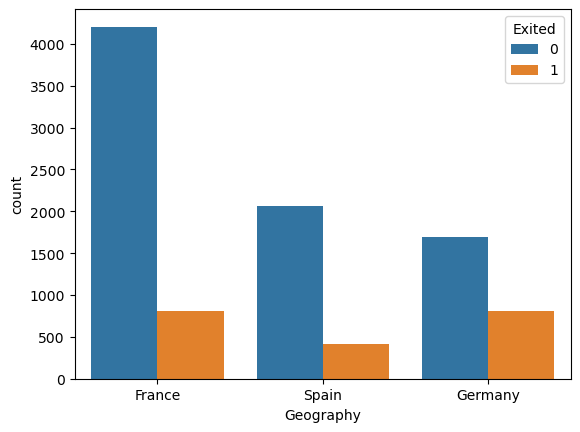

In [24]:
sns.countplot(x='Geography',hue='Exited',data=df)
plt.show()

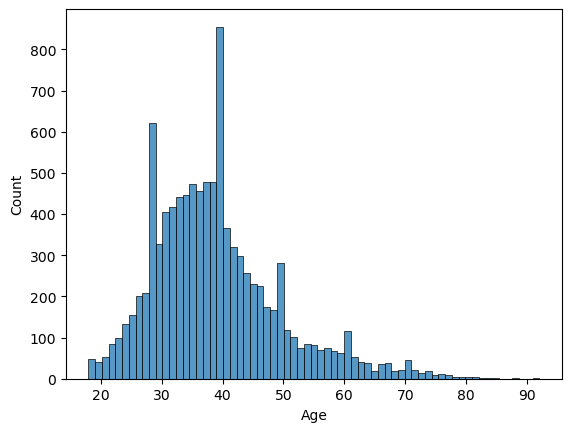

In [25]:
sns.histplot(df['Age'])
plt.show()

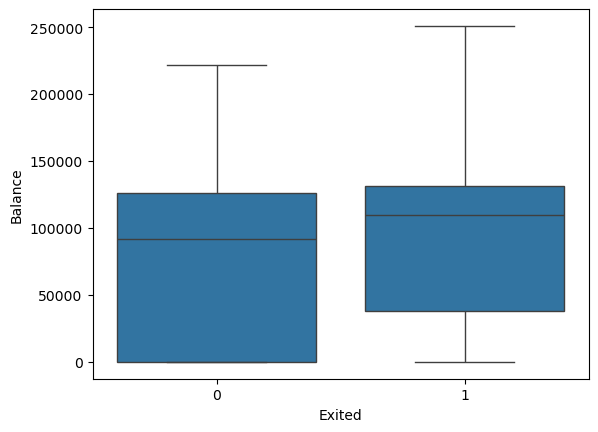

In [26]:
sns.boxplot(x='Exited',y='Balance',data=df)
plt.show()

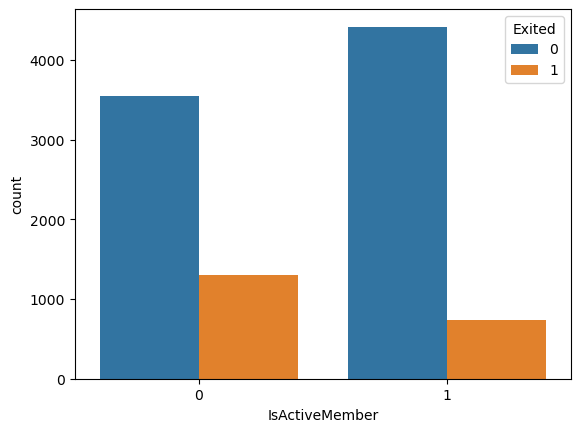

In [27]:
sns.countplot(x='IsActiveMember',hue='Exited',data=df)
plt.show()

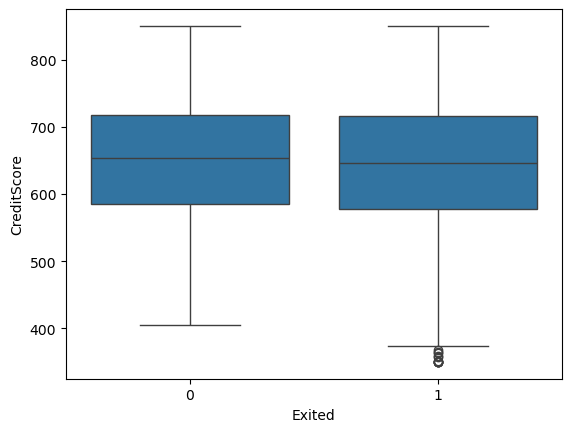

In [28]:
sns.boxplot(x='Exited',y='CreditScore',data=df)
plt.show()

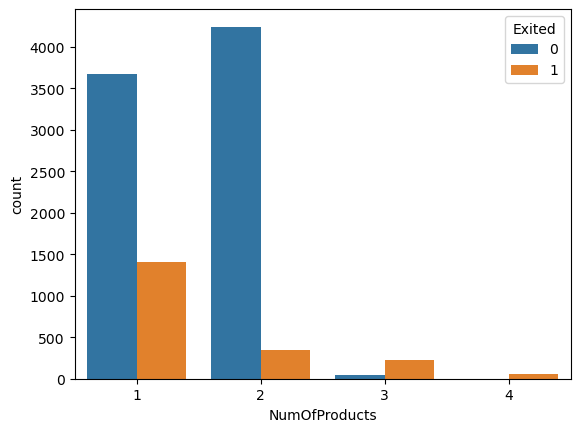

In [29]:
sns.countplot(x='NumOfProducts',hue='Exited',data=df)
plt.show()

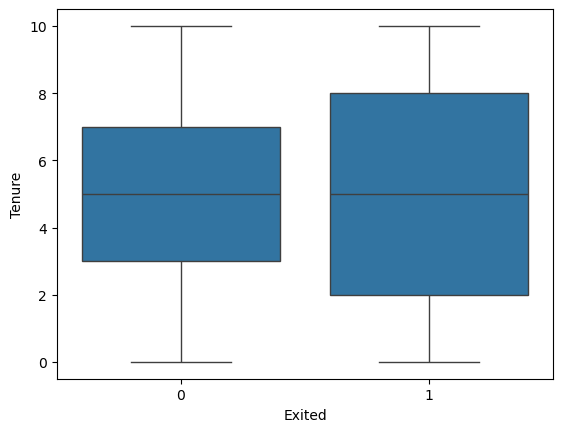

In [30]:
sns.boxplot(x='Exited',y='Tenure',data=df)
plt.show()

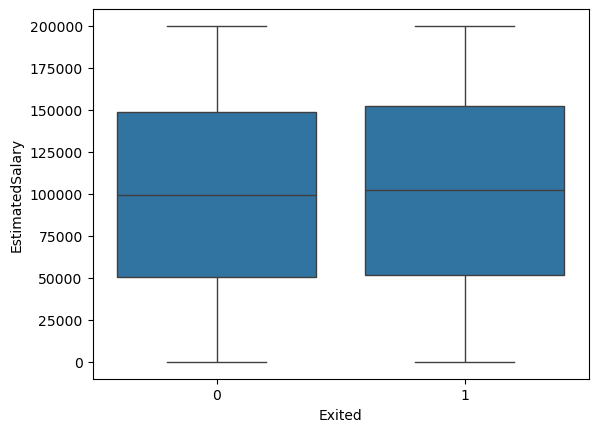

In [31]:
sns.boxplot(x='Exited',y='EstimatedSalary',data=df)
plt.show()

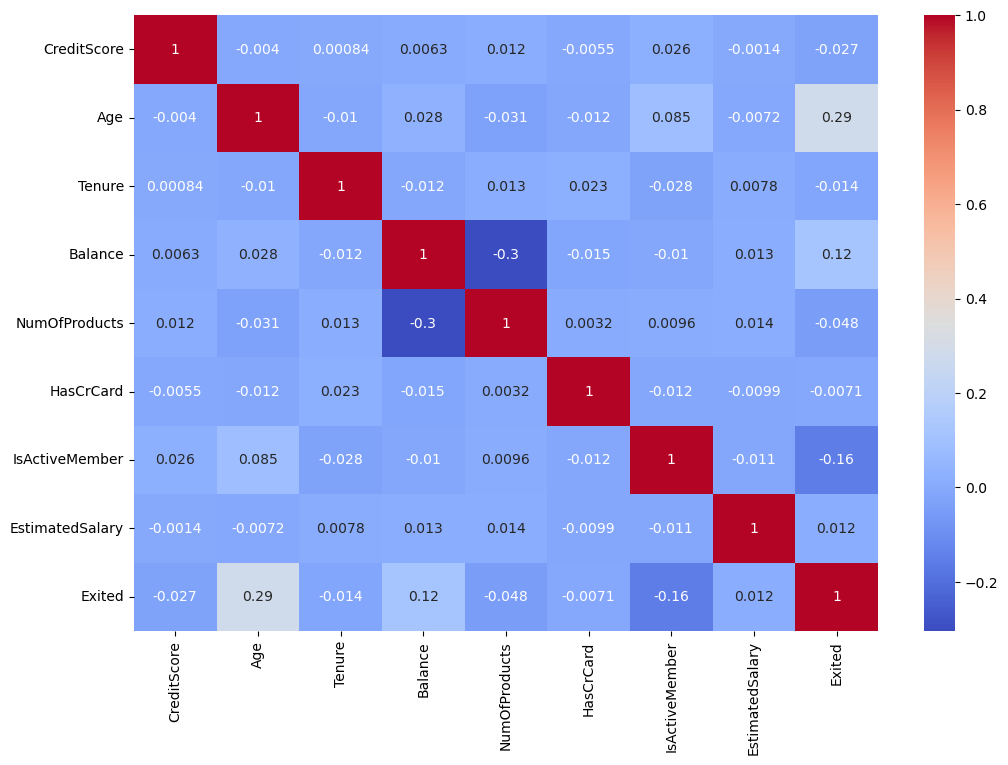

In [32]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm')
plt.show()

In [34]:
df=pd.get_dummies(df,drop_first=True)

In [35]:
x=df.drop('Exited',axis=1)
y=df['Exited']

In [41]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [42]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [43]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(max_iter=5000,solver='liblinear')
model.fit(x_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'liblinear'
,max_iter,5000
,multi_class,'deprecated'


In [44]:
y_pred=model.predict(x_test)

In [45]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.811

In [46]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test,y_pred)

array([[1543,   64],
       [ 314,   79]])

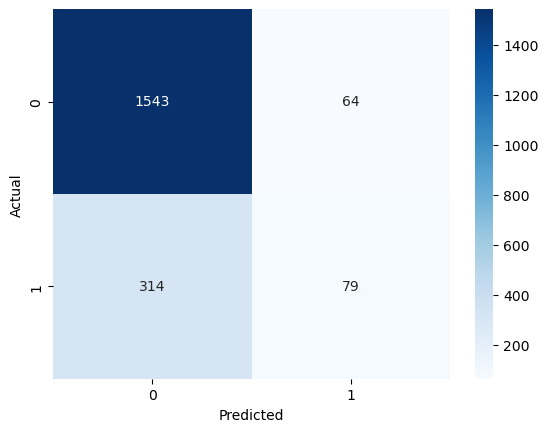

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [50]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.83      0.96      0.89      1607
           1       0.55      0.20      0.29       393

    accuracy                           0.81      2000
   macro avg       0.69      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000



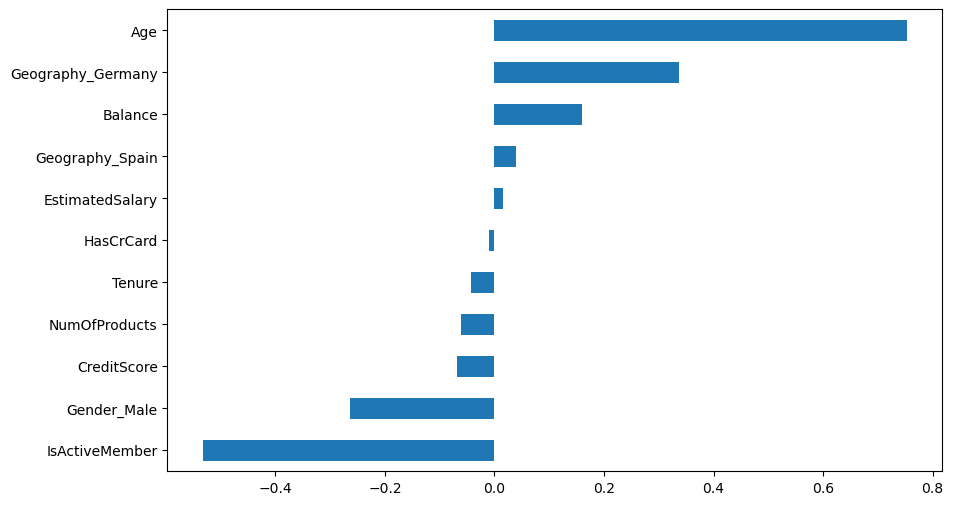

In [51]:
import pandas as pd
feature_importance=pd.Series(model.coef_[0],index=x.columns)
feature_importance.sort_values().plot(kind='barh',figsize=(10,6))
plt.show()

In [52]:
from sklearn.ensemble import RandomForestClassifier
rf=RandomForestClassifier()
rf.fit(x_train,y_train)
y_pred_rf=rf.predict(x_test)

In [53]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred_rf)

0.8655

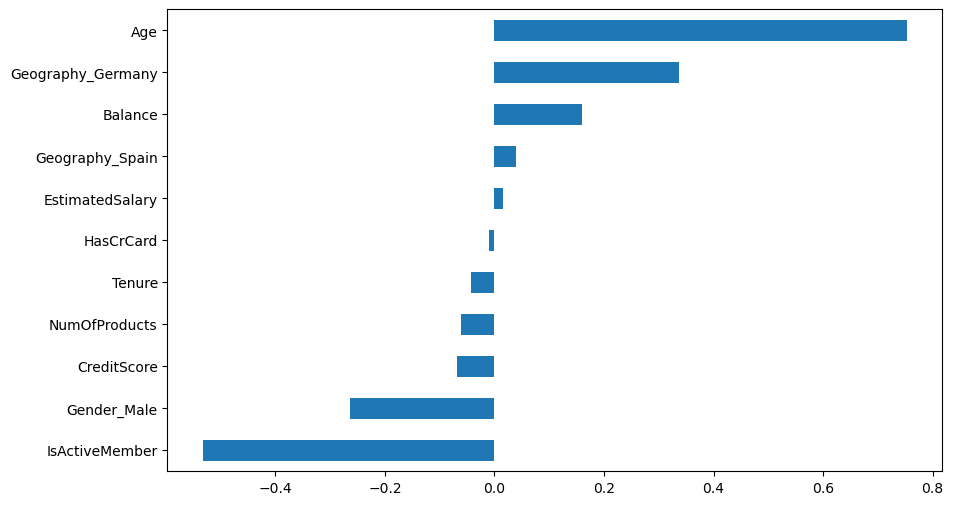

In [54]:
import pandas as pd
feature_importance=pd.Series(model.coef_[0],index=x.columns)
feature_importance.sort_values().plot(kind='barh',figsize=(10,6))
plt.show()

In [55]:
from sklearn.metrics import accuracy_score
log_acc=accuracy_score(y_test,y_pred)
log_acc

0.811

In [56]:
rf_acc=accuracy_score(y_test,y_pred_rf)
rf_acc

0.8655

In [57]:
import pandas as pd
comparison=pd.DataFrame({'Model':['Logistic Regression','Random Forest'],'Accuracy':[log_acc,rf_acc]})
comparison

,Model,Accuracy
0,Logistic Regression,0.8110
1,Random Forest,0.8655


In [69]:
##Conclusion:
##Random Forest was selected as final model with 86.55% accuracy.

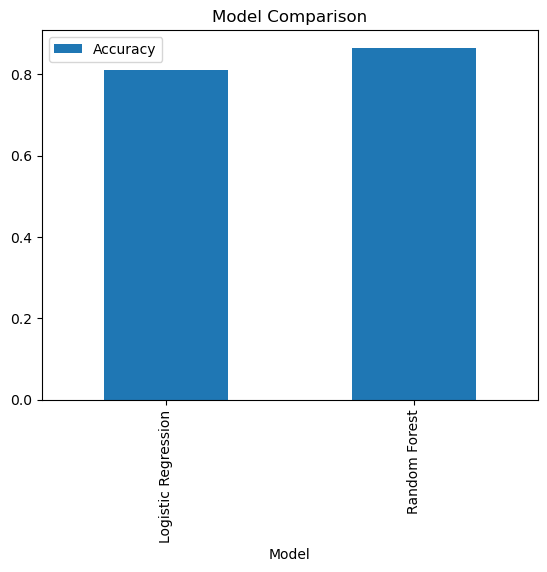

In [58]:
comparison.plot(x='Model',y='Accuracy',kind='bar')
plt.title("Model Comparison")
plt.show()

In [65]:
## Business Recommendations

##Based on the analysis, the following recommendations are suggested:

##1. Focus on inactive customers by providing personalized offers and reminders.
##2. Offer special benefits and loyalty programs for older customers.
##3. Improve customer service and engagement in Germany to reduce churn.
##4. Encourage customers to use multiple bank products.
##5. Provide incentives for customers with high balances to retain them.

In [66]:
##Conclusion

##In this project, customer churn analysis was performed using bank customer data to identify factors influencing customer attrition. Through exploratory data analysis and machine learning models, key patterns affecting churn were identified.

##The analysis revealed that older customers, inactive members, and customers with fewer products were more likely to leave the bank. Additionally, customers from Germany and those with higher account balances showed a higher churn rate.

##Two machine learning models, Logistic Regression and Random Forest, were built and evaluated. Random Forest achieved better performance with an accuracy of **86.55%**, making it the preferred model for predicting customer churn.

##Based on these findings, banks can take proactive measures such as improving engagement with inactive customers, offering personalized benefits, encouraging multi-product usage, and enhancing customer experience in high-churn regions. Implementing these strategies can help reduce customer churn and improve customer retention.
